# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [1]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [2]:
#!rm SUSY.csv

In [3]:
#!gunzip SUSY.csv.gz

In [4]:
ls -lh

total 6962072
-rw-r--r--@ 1 mariamadiallo  staff   149K Oct  9 20:05 Lab.7.pdf
-rw-r--r--  1 mariamadiallo  staff    43K Nov 16 23:32 Lab.7.solution.ipynb
-rw-r--r--  1 mariamadiallo  staff   228M Nov 16 23:18 SUSY-small.csv
-rwx------  1 mariamadiallo  staff   2.2G May 22  2023 SUSY.csv*
-rw-r--r--  1 mariamadiallo  staff   880M Nov 14 23:07 susy.zip


The data is provided as a comma separated file.

In [5]:
filename="SUSY-small.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY-small.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [6]:
!ls -lh

total 6962072
-rw-r--r--@ 1 mariamadiallo  staff   149K Oct  9 20:05 Lab.7.pdf
-rw-r--r--  1 mariamadiallo  staff    43K Nov 16 23:32 Lab.7.solution.ipynb
-rw-r--r--  1 mariamadiallo  staff   228M Nov 16 23:18 SUSY-small.csv
-rwx------  1 mariamadiallo  staff   2.2G May 22  2023 SUSY.csv
-rw-r--r--  1 mariamadiallo  staff   880M Nov 14 23:07 susy.zip


We see that we have 5 million datapoints.

In [7]:
!wc -l SUSY.csv

 5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [8]:
!head -500000 SUSY.csv > SUSY-small.csv

In [9]:
ls -lh

total 6962072
-rw-r--r--@ 1 mariamadiallo  staff   149K Oct  9 20:05 Lab.7.pdf
-rw-r--r--  1 mariamadiallo  staff    43K Nov 16 23:32 Lab.7.solution.ipynb
-rw-r--r--  1 mariamadiallo  staff   228M Nov 16 23:32 SUSY-small.csv
-rwx------  1 mariamadiallo  staff   2.2G May 22  2023 SUSY.csv*
-rw-r--r--  1 mariamadiallo  staff   880M Nov 14 23:07 susy.zip


In [10]:
! wc -l SUSY-small.csv

  500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [11]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [12]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [13]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [14]:
FeatureNames

['M_R',
 'cos_theta_r1',
 'axial_MET',
 'R',
 'S_R',
 'M_TR_2',
 'MET_rel',
 'M_Delta_R',
 'dPhi_r_b',
 'MT2']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [16]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [17]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [18]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


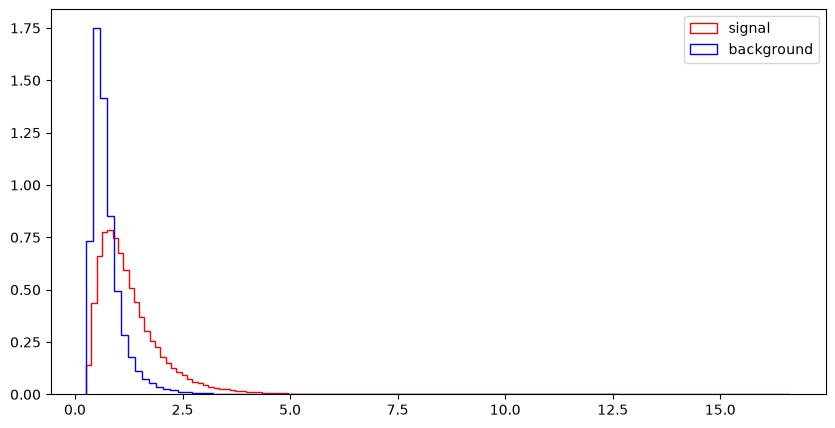

l_1_eta


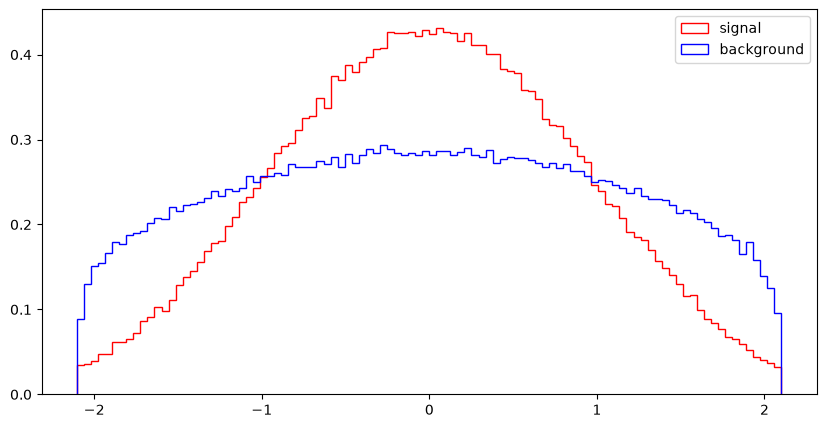

l_1_phi


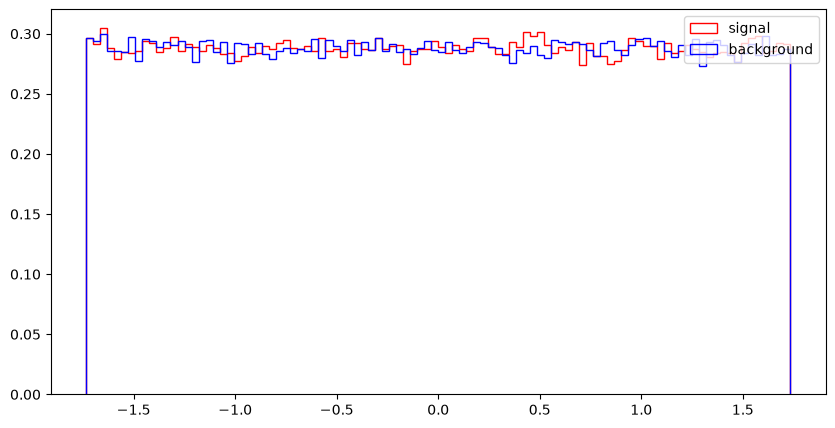

l_2_pT


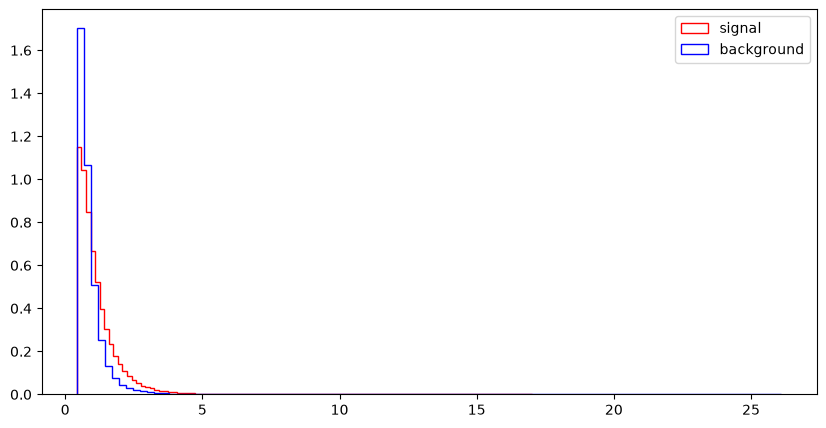

l_2_eta


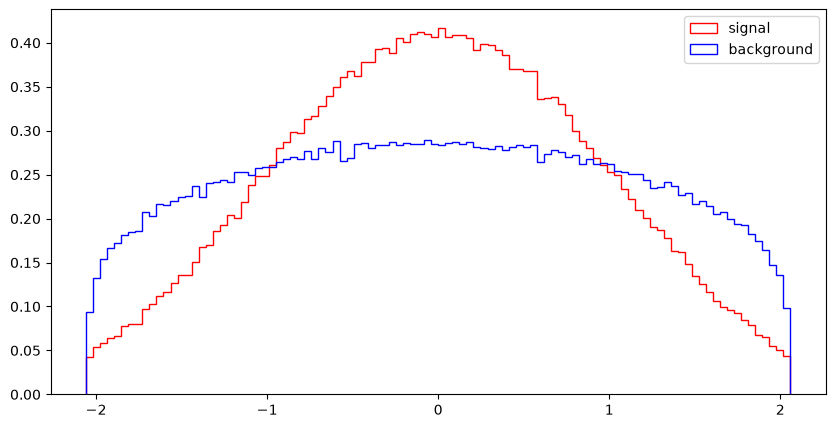

l_2_phi


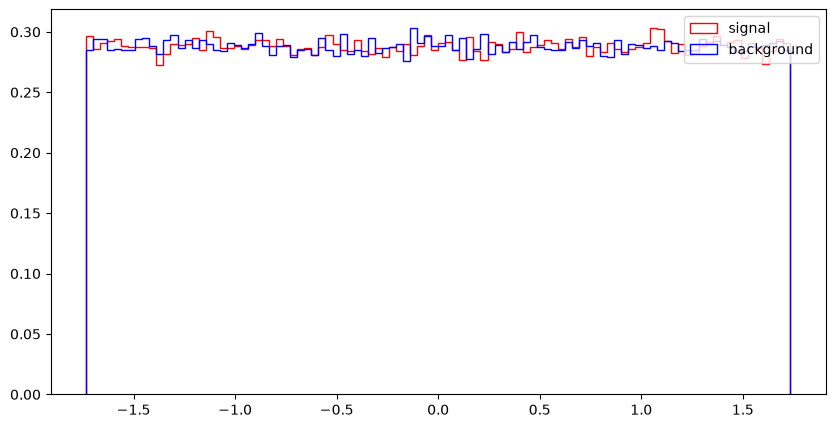

MET


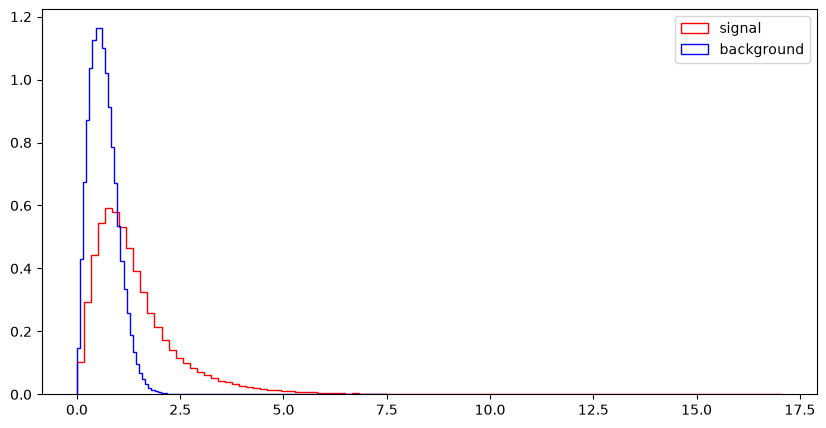

MET_phi


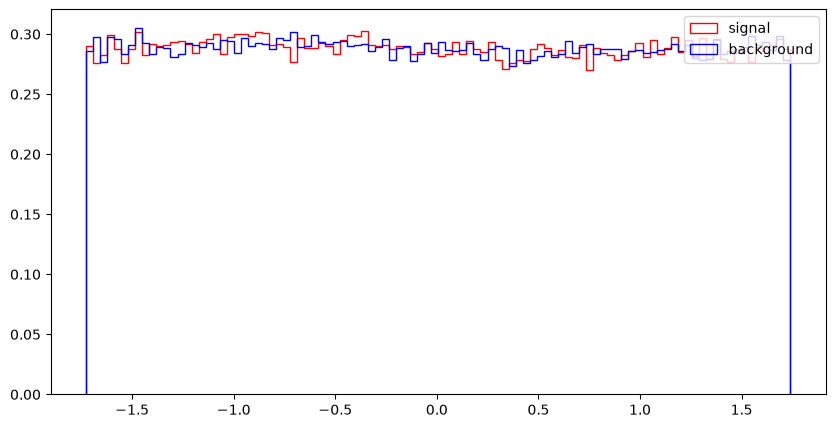

MET_rel


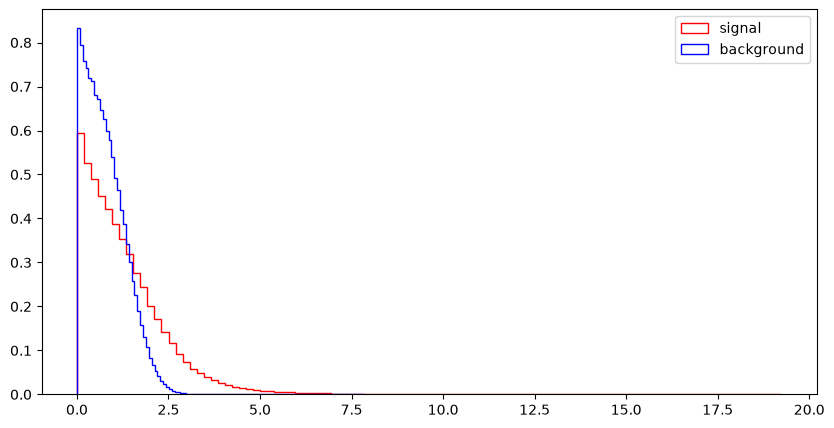

axial_MET


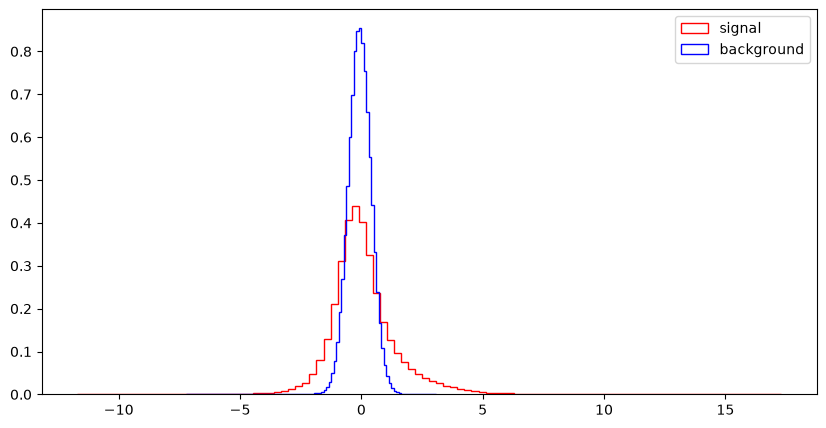

M_R


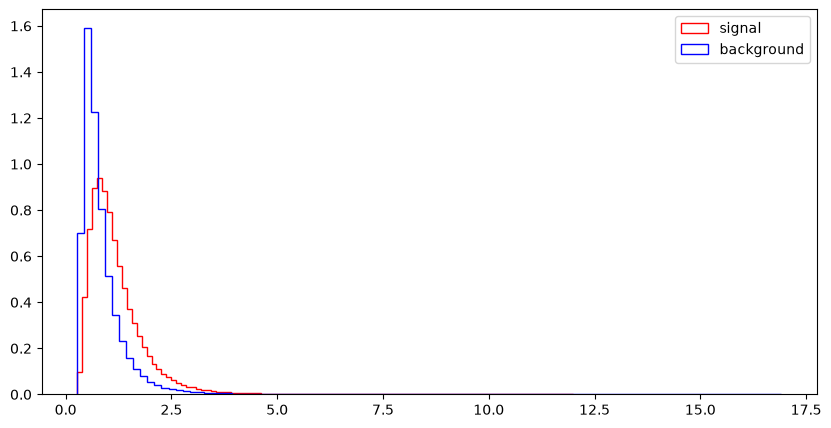

M_TR_2


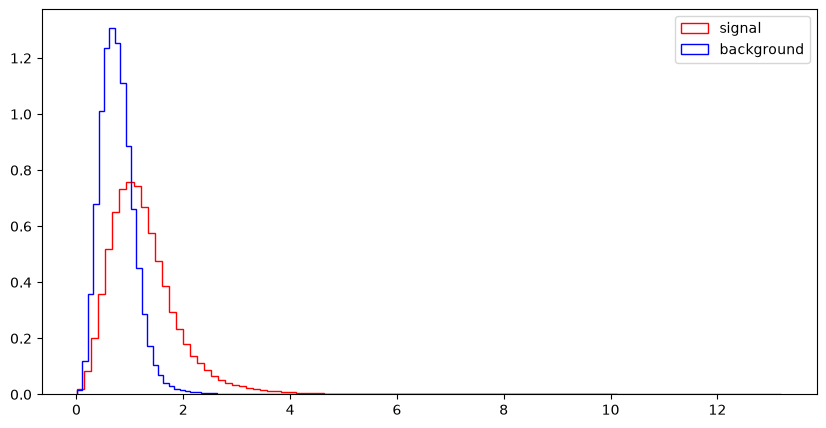

R


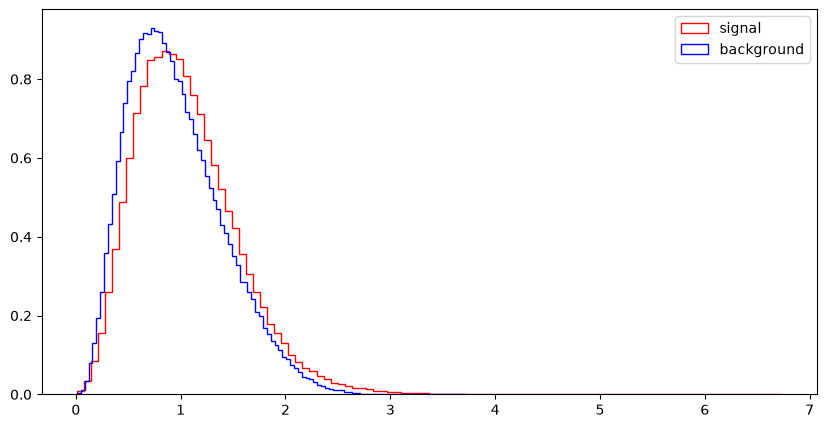

MT2


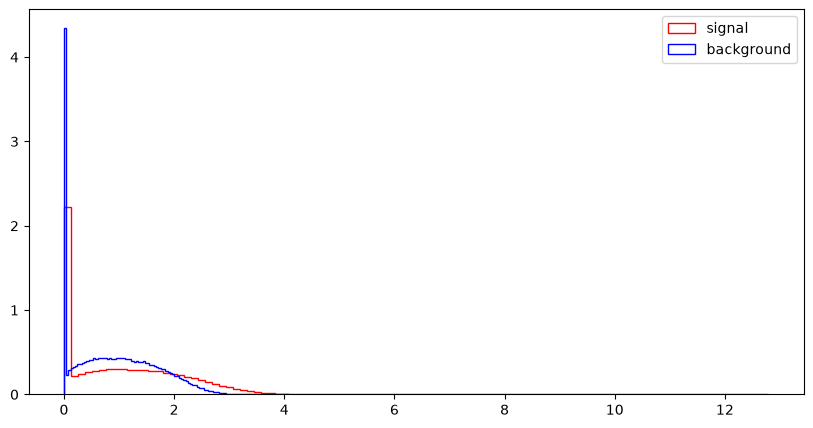

S_R


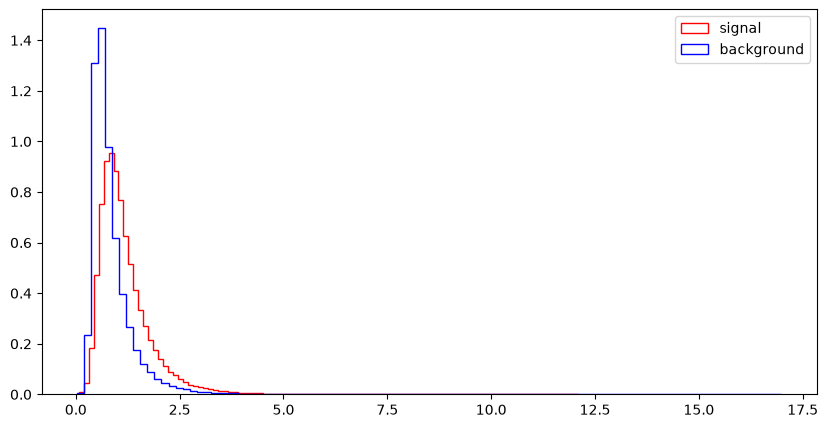

M_Delta_R


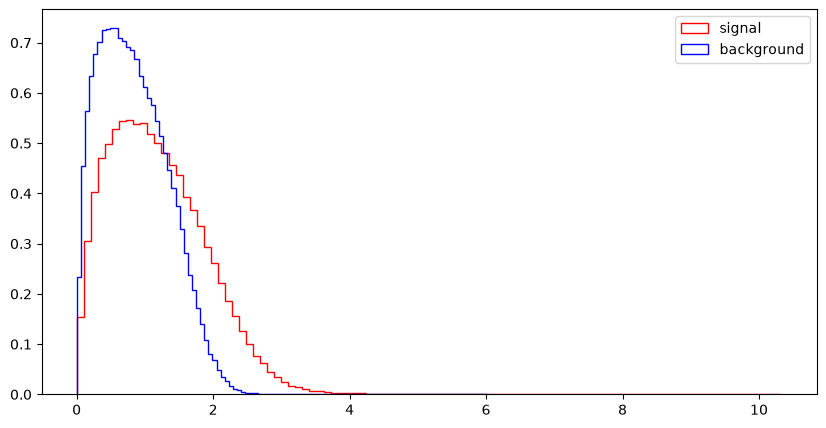

dPhi_r_b


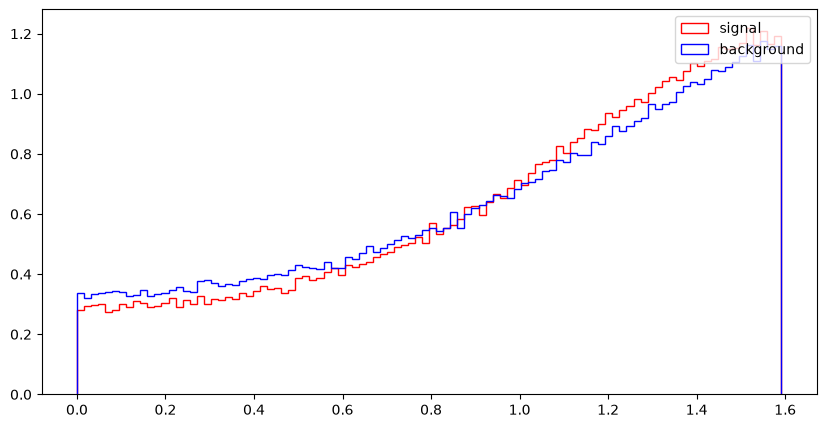

cos_theta_r1


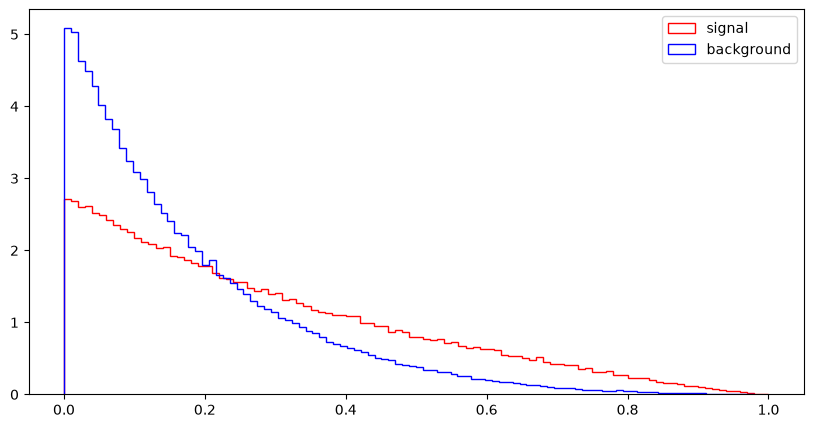

In [19]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

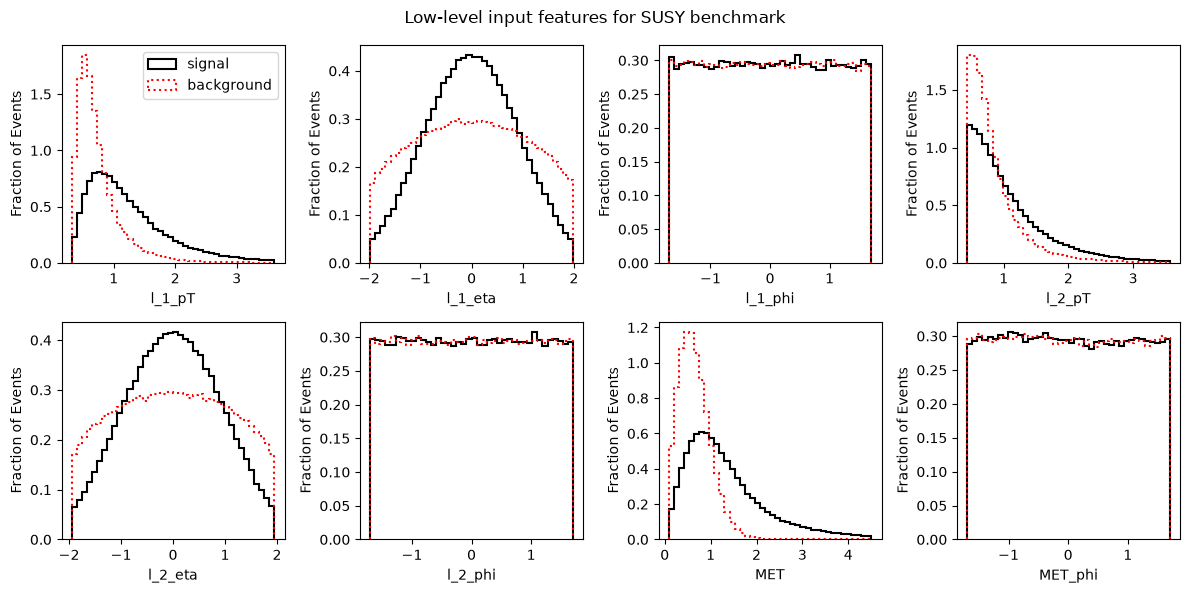

In [20]:
# Figure 5 - low-level features

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.flatten()

for i, var in enumerate(RawNames):

    low = df[var].quantile(0.01)
    high = df[var].quantile(0.99)

    axes[i].hist(df_sig[var], bins=40, range=(low, high),
                 density=True, histtype="step",
                 color="black", linewidth=1.5,
                 label="signal")

    axes[i].hist(df_bkg[var], bins=40, range=(low, high),
                 density=True, histtype="step",
                 color="red", linestyle="dotted",
                 linewidth=1.5, label="background")

    axes[i].set_xlabel(var)
    axes[i].set_ylabel("Fraction of Events")

axes[0].legend()

plt.suptitle("Low-level input features for SUSY benchmark")
plt.tight_layout()
plt.show()

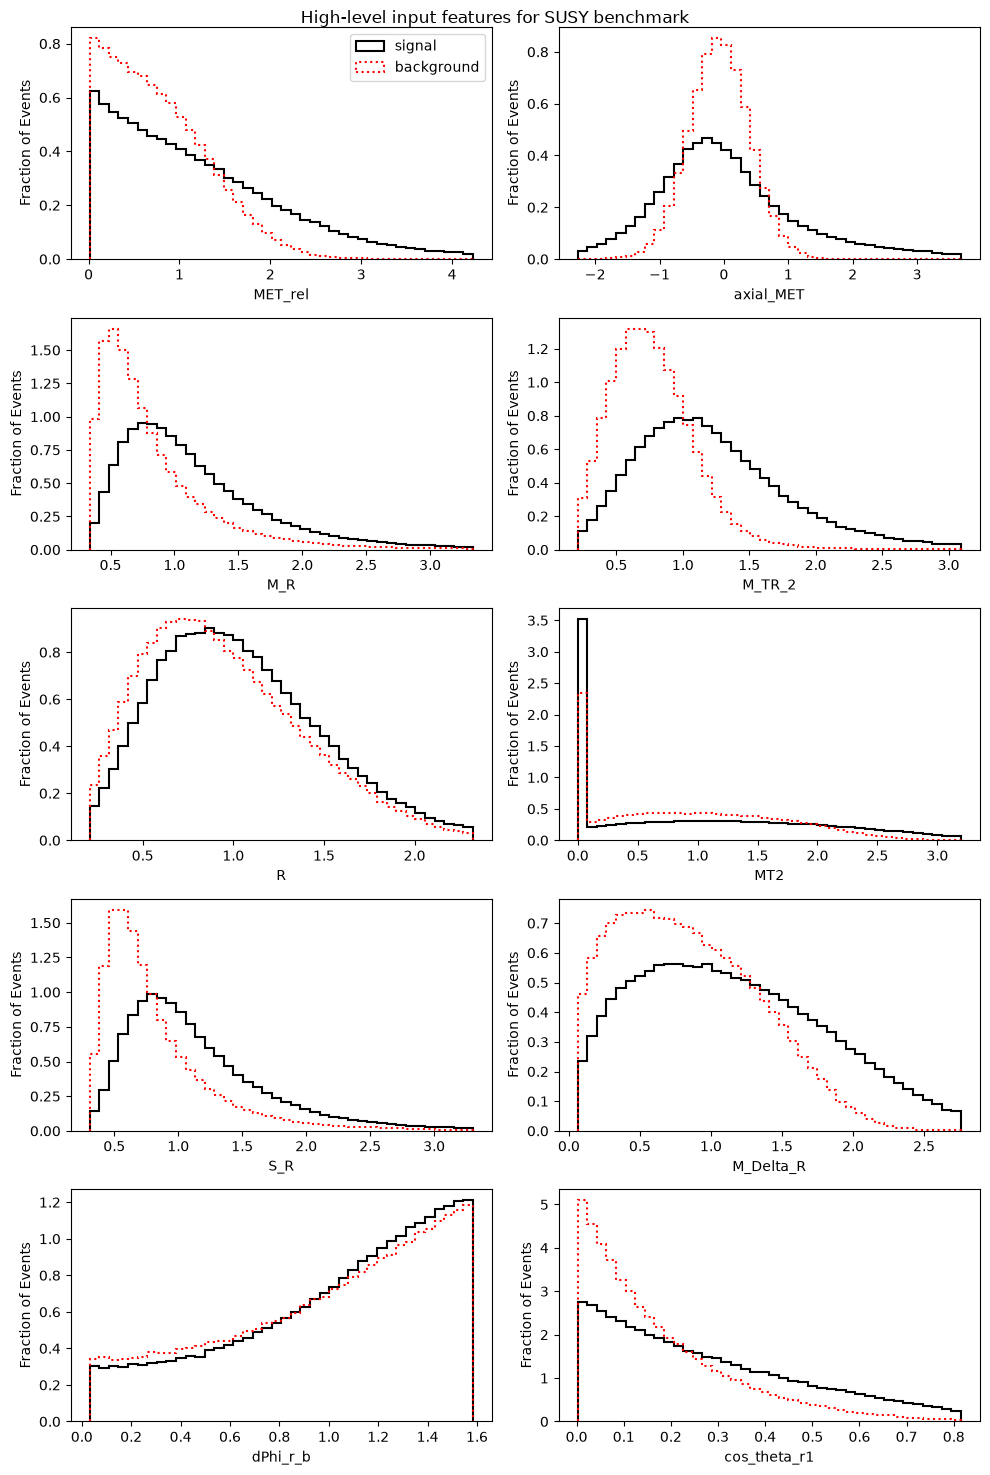

In [21]:
# Figure 6 - high-level features

HighLevelNames = VarNames[9:]

fig, axes = plt.subplots(5, 2, figsize=(10, 15))
axes = axes.flatten()

for i, var in enumerate(HighLevelNames):

    low = df[var].quantile(0.01)
    high = df[var].quantile(0.99)

    axes[i].hist(df_sig[var], bins=40, range=(low, high),
                 density=True, histtype="step",
                 color="black", linewidth=1.5,
                 label="signal")

    axes[i].hist(df_bkg[var], bins=40, range=(low, high),
                 density=True, histtype="step",
                 color="red", linestyle="dotted",
                 linewidth=1.5, label="background")

    axes[i].set_xlabel(var)
    axes[i].set_ylabel("Fraction of Events")

axes[0].legend()

plt.suptitle("High-level input features for SUSY benchmark")
plt.tight_layout()
plt.show()

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

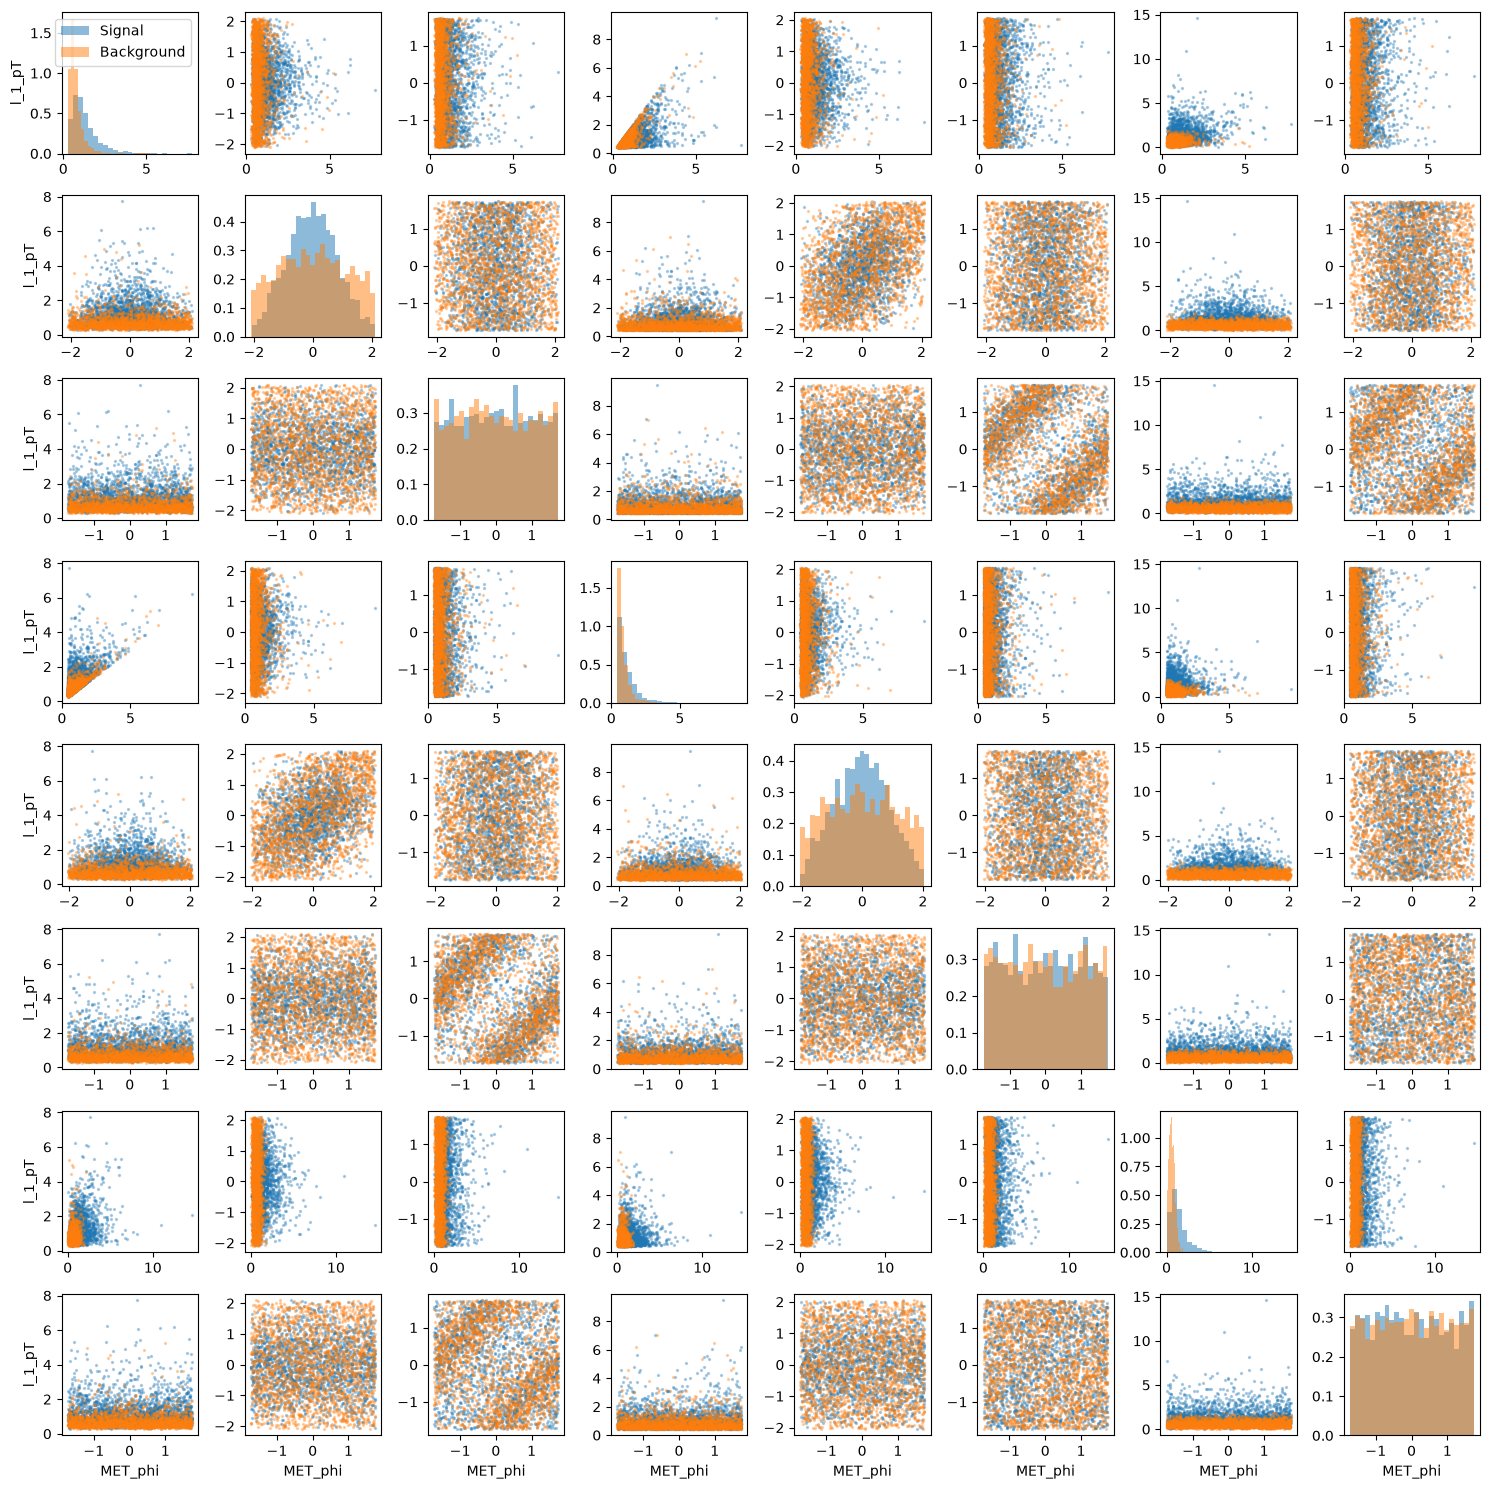

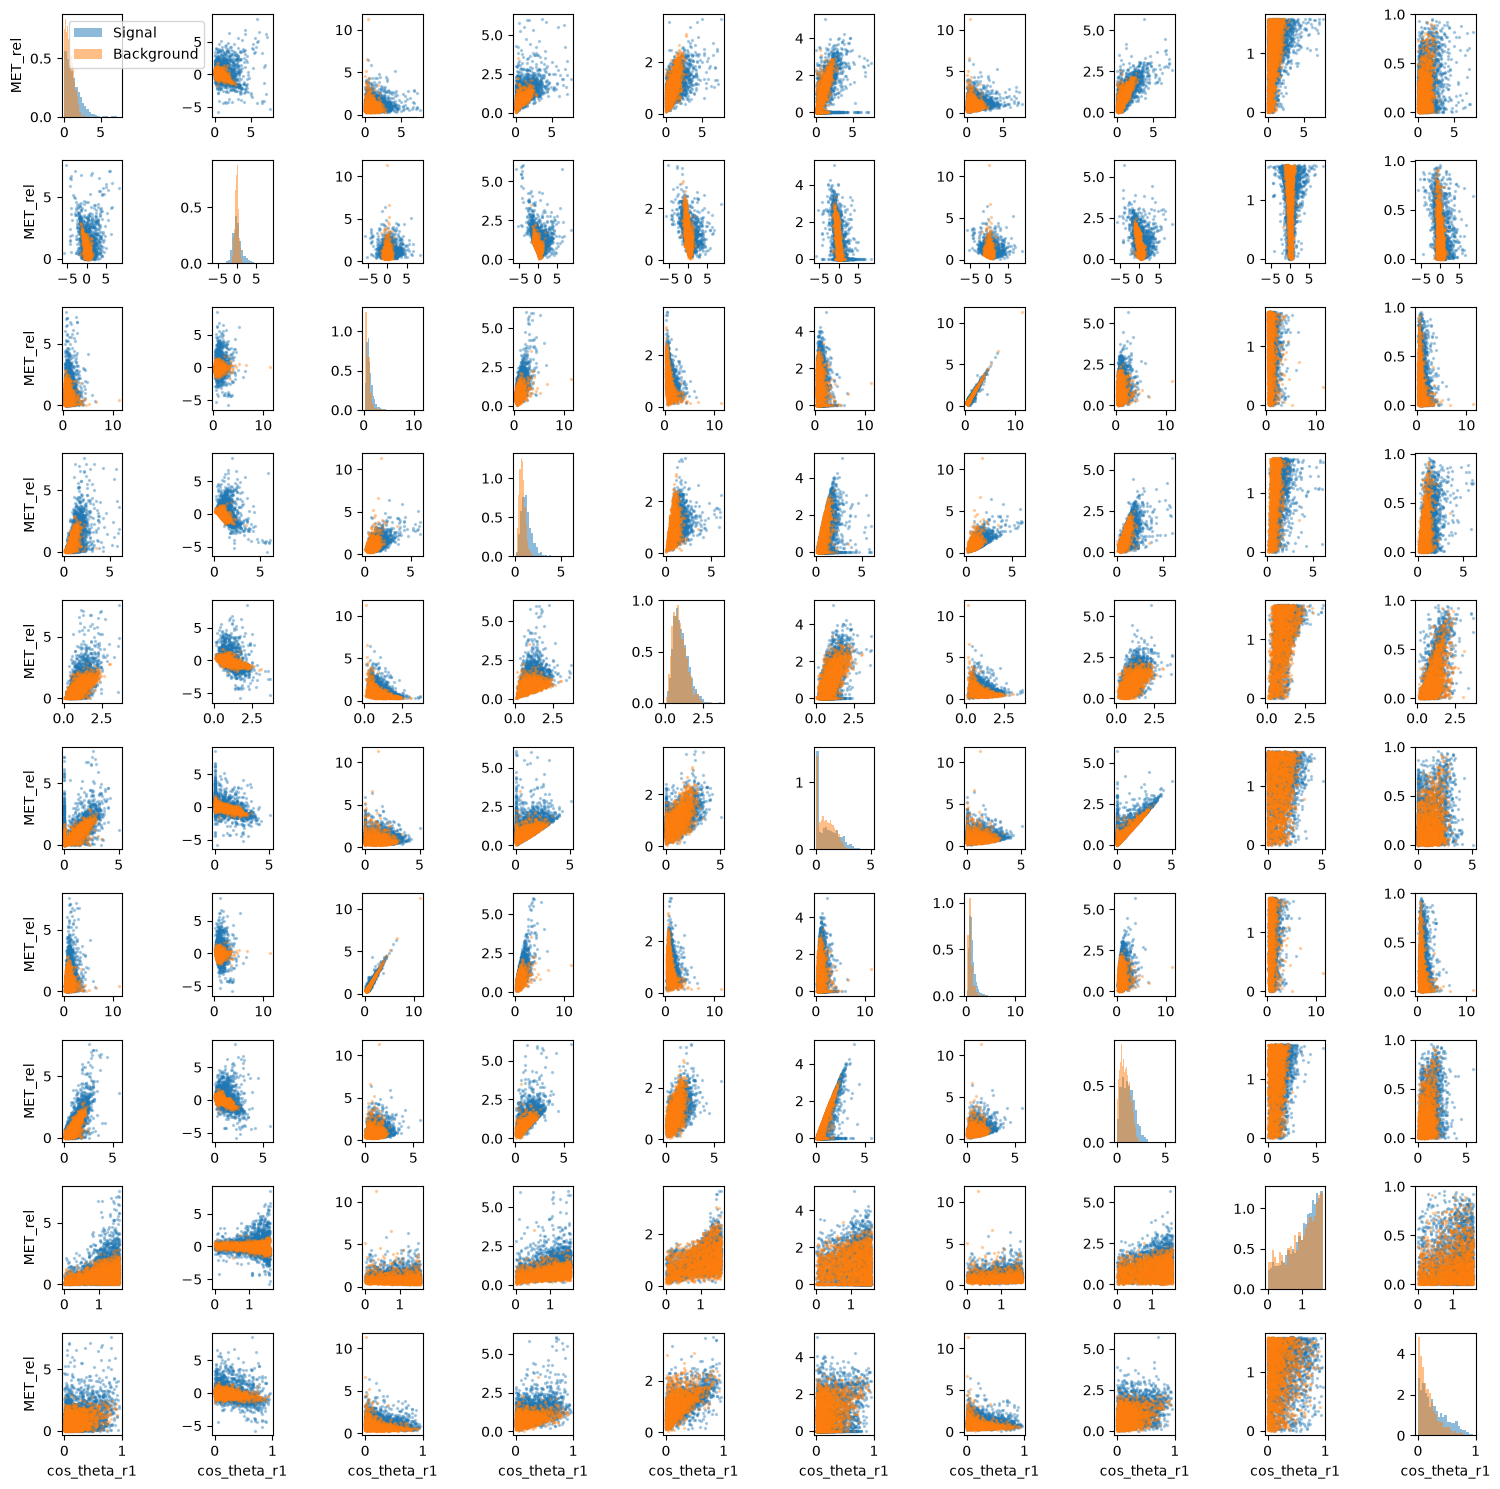

In [22]:
#part a 
def pair_plot(df, columns, selections, sample_size=2000):

    n_columns = len(columns)
    plt.figure(figsize=(15,15))

    plot_i = 0

    for i, x_var_name in enumerate(columns):
        for j, y_var_name in enumerate(columns):

            plot_i += 1
            plt.subplot(n_columns, n_columns, plot_i)

            if i == j:
                for label, selection in selections.items():
                    sample = df[selection].sample(
                        min(sample_size, sum(selection)),
                        random_state=1
                    )

                    plt.hist(sample[x_var_name],
                             bins=25,
                             alpha=0.5,
                             density=True,
                             label=label)

            else:
                for label, selection in selections.items():
                    sample = df[selection].sample(
                        min(sample_size, sum(selection)),
                        random_state=1
                    )

                    plt.scatter(sample[x_var_name],
                                sample[y_var_name],
                                s=2,
                                alpha=0.3,
                                label=label)

            if i == 0 and j == 0:
                plt.legend()

            if i == n_columns - 1:
                plt.xlabel(x_var_name)

            if j == 0:
                plt.ylabel(y_var_name)

    plt.tight_layout()
    plt.show()


selection_dict = {
    "Signal": df["signal"] == 1,
    "Background": df["signal"] == 0
}
low_vars = RawNames
high_vars = HighLevelNames

pair_plot(df, low_vars, selection_dict)
pair_plot(df, high_vars, selection_dict)

#part b
I sped up the pair plots by using a random sample of 2,000 events instead of all 500,000 rows. Another way to speed up the histograms would be to calculate the bin counts once and reuse them instead of looping through the full dataset each time.

#part c The observables that appear to separate signal from background best are l_1_pT, l_2_pT, MET, MET_rel, and MT2 because their distributions show the clearest differences between the signal and background samples.

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

In [23]:
%pip install tabulate


[notice] A new release of pip is available: 23.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [24]:
import numpy as np
import tabulate
from IPython.display import HTML, display

In [25]:
all_vars = VarNames[1:]

cov_all = np.cov(df[all_vars], rowvar=False)
corr_all = np.corrcoef(df[all_vars], rowvar=False)

cov_low = np.cov(df[RawNames], rowvar=False)
corr_low = np.corrcoef(df[RawNames], rowvar=False)

cov_high = np.cov(df[HighLevelNames], rowvar=False)
corr_high = np.corrcoef(df[HighLevelNames], rowvar=False)
cov_all
corr_all

array([[ 1.00000000e+00, -5.78921273e-04,  1.11842464e-04,
         6.83953780e-01, -5.08594430e-04,  1.07636651e-03,
         3.82675470e-01, -1.36774936e-03,  1.60428419e-01,
        -1.41964506e-02,  8.51136209e-01,  7.22753542e-01,
        -1.85501073e-01, -2.11139596e-02,  8.10678230e-01,
         2.29308652e-01, -1.57453882e-01,  1.64500727e-01],
       [-5.78921273e-04,  1.00000000e+00, -8.54097003e-04,
        -2.49206493e-04,  4.06167328e-01, -1.03780753e-03,
        -2.45384543e-03, -5.86734524e-04, -1.53823223e-03,
        -1.10355390e-03, -8.82482751e-04, -1.14840487e-03,
         6.38709703e-04,  4.96240629e-04, -9.75150826e-04,
        -1.58062104e-03, -1.69395415e-03,  1.62871235e-03],
       [ 1.11842464e-04, -8.54097003e-04,  1.00000000e+00,
         2.00884136e-03,  2.49438239e-04, -2.65777410e-01,
         8.76045628e-04, -1.84133143e-01,  7.92724671e-04,
        -1.86397989e-03,  1.69419599e-03,  1.49177313e-03,
         4.27421600e-04,  1.23207194e-03,  2.36358093e

In [26]:
def show_matrix(matrix, names, title):
    print(title)

    table = []

    for i, row in enumerate(matrix):
        table.append([names[i]] + list(np.round(row, 3)))

    display(
        HTML(
            tabulate.tabulate(
                table,
                headers=[""] + names,
                tablefmt="html"
            )
        )
    )


show_matrix(cov_all, all_vars, "Covariance Matrix - All Observables")
show_matrix(corr_all, all_vars, "Correlation Matrix - All Observables")

show_matrix(cov_low, RawNames, "Covariance Matrix - Low-Level Features")
show_matrix(corr_low, RawNames, "Correlation Matrix - Low-Level Features")

show_matrix(cov_high, HighLevelNames, "Covariance Matrix - High-Level Features")
show_matrix(corr_high, HighLevelNames, "Correlation Matrix - High-Level Features")

Covariance Matrix - All Observables


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001,0.098,-0.01,0.364,0.287,-0.06,-0.012,0.343,0.098,-0.047,0.022
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001,-0.001,-0.001,-0.001,-0.001,0,0,-0.001,-0.001,-0.001,0
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185,0.001,-0.002,0.001,0.001,0,0.001,0.001,0.001,0.001,0
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002,-0.001,0.051,0.325,0.163,-0.099,-0.069,0.322,0.006,-0.004,-0.028
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0,0.001,-0.001,-0.001,0,0,0.001,-0.001,0.001,-0,0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035,0.001,-0.002,0.001,0.001,0.001,0.002,0.001,0.001,-0,0
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.073
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003,-0.005,-0,-0.001,-0.001,-0,0,-0.002,-0.001,-0.002,0
MET_rel,0.098,-0.001,0.001,-0.001,0.001,0.001,0.546,-0.005,0.79,-0.12,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.01,-0.001,-0.002,0.051,-0.001,-0.002,0.154,-0,-0.12,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054


Correlation Matrix - All Observables


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001,0.16,-0.014,0.851,0.723,-0.186,-0.021,0.811,0.229,-0.157,0.165
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001,-0.002,-0.001,-0.001,-0.001,0.001,0,-0.001,-0.002,-0.002,0.002
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184,0.001,-0.002,0.002,0.001,0,0.001,0.002,0.001,0.002,0.001
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002,-0.001,0.078,0.797,0.43,-0.324,-0.123,0.799,0.014,-0.013,-0.217
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0,0.001,-0.001,-0.001,0,0.001,0.002,-0.001,0.001,-0.001,0.001
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035,0.002,-0.002,0.001,0.001,0.001,0.003,0.001,0.002,-0.001,0
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003,0.704,0.176,0.264,0.72,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1,-0.005,-0,-0.002,-0.002,-0,0,-0.003,-0.001,-0.004,0.001
MET_rel,0.16,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272


Covariance Matrix - Low-Level Features


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003


... (2 outputs left out)

Covariance Matrix - High-Level Features


,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.79,-0.12,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.12,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054
M_R,0.044,0.017,0.392,0.21,-0.113,-0.037,0.38,0.074,-0.029,-0.014
M_TR_2,0.302,-0.185,0.21,0.338,0.104,0.189,0.228,0.242,0.058,0.052
R,0.249,-0.181,-0.113,0.104,0.222,0.232,-0.083,0.165,0.087,0.058
MT2,0.409,-0.461,-0.037,0.189,0.232,0.738,-0.011,0.433,0.021,0.045
S_R,0.082,-0.041,0.38,0.228,-0.083,-0.011,0.382,0.096,-0.003,-0.01
M_Delta_R,0.415,-0.233,0.074,0.242,0.165,0.433,0.096,0.389,0.042,0.039
dPhi_r_b,0.146,-0.025,-0.029,0.058,0.087,0.021,-0.003,0.042,0.19,0.009
cos_theta_r1,0.055,-0.054,-0.014,0.052,0.058,0.045,-0.01,0.039,0.009,0.039


Correlation Matrix - High-Level Features


,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272
M_R,0.078,0.027,1,0.577,-0.383,-0.068,0.981,0.189,-0.106,-0.116
M_TR_2,0.584,-0.317,0.577,1,0.38,0.379,0.635,0.668,0.229,0.451
R,0.595,-0.383,-0.383,0.38,1,0.574,-0.287,0.564,0.424,0.627
MT2,0.535,-0.535,-0.068,0.379,0.574,1,-0.021,0.809,0.056,0.264
S_R,0.15,-0.067,0.981,0.635,-0.287,-0.021,1,0.249,-0.013,-0.085
M_Delta_R,0.748,-0.373,0.189,0.668,0.564,0.809,0.249,1,0.155,0.319
dPhi_r_b,0.378,-0.057,-0.106,0.229,0.424,0.056,-0.013,0.155,1,0.106
cos_theta_r1,0.316,-0.272,-0.116,0.451,0.627,0.264,-0.085,0.319,0.106,1


In [27]:
def covariance_correlation_tables(df, variables):

    covariance = np.cov(df[variables], rowvar=False)
    correlation = np.corrcoef(df[variables], rowvar=False)

    print("Covariance Matrix")
    table = []

    for i, row in enumerate(covariance):
        table.append([variables[i]] + list(np.round(row, 3)))

    display(
        HTML(
            tabulate.tabulate(
                table,
                headers=[""] + variables,
                tablefmt="html"
            )
        )
    )

    print("Correlation Matrix")
    table = []

    for i, row in enumerate(correlation):
        table.append([variables[i]] + list(np.round(row, 3)))

    display(
        HTML(
            tabulate.tabulate(
                table,
                headers=[""] + variables,
                tablefmt="html"
            )
        )
    )

In [28]:
covariance_correlation_tables(df, RawNames)

Covariance Matrix


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003


Correlation Matrix


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1


Hint: Example code for embedding a `tabulate` table into a notebook:

In [29]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

X,Y,Z
A,1,2
C,3,4
D,5,6




### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.


### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

In [30]:
# 5.1

observables = VarNames[1:]

sample = df.sample(n=20000, random_state=1)

for variable in observables:

    signal_values = sample[sample["signal"] == 1][variable]
    background_values = sample[sample["signal"] == 0][variable]

    print(variable)
    print(" signal mean:", round(signal_values.mean(), 3))
    print(" background mean:", round(background_values.mean(), 3))
    print()

l_1_pT
 signal mean: 1.296
 background mean: 0.748

l_1_eta
 signal mean: -0.001
 background mean: -0.009

l_1_phi
 signal mean: 0.004
 background mean: 0.006

l_2_pT
 signal mean: 1.139
 background mean: 0.874

l_2_eta
 signal mean: 0.002
 background mean: -0.005

l_2_phi
 signal mean: 0.005
 background mean: -0.005

MET
 signal mean: 1.41
 background mean: 0.642

MET_phi
 signal mean: 0.011
 background mean: -0.003

MET_rel
 signal mean: 1.255
 background mean: 0.765

axial_MET
 signal mean: 0.083
 background mean: -0.065

M_R
 signal mean: 1.189
 background mean: 0.841

M_TR_2
 signal mean: 1.268
 background mean: 0.766

R
 signal mean: 1.047
 background mean: 0.948

MT2
 signal mean: 1.059
 background mean: 0.933

S_R
 signal mean: 1.178
 background mean: 0.846

M_Delta_R
 signal mean: 1.179
 background mean: 0.839

dPhi_r_b
 signal mean: 1.011
 background mean: 0.983

cos_theta_r1
 signal mean: 0.283
 background mean: 0.177



#5.1 
This is what I believe woulld be optimal for each section 
l_1_pT: x > x_c  
l_1_eta: |x - μ| < x_c  
l_1_phi: |x - μ| < x_c  
l_2_pT: x > x_c  
l_2_eta: |x - μ| < x_c  
l_2_phi: |x - μ| < x_c  
MET: x > x_c  
MET_phi: |x - μ| < x_c  
MET_rel: x > x_c  
axial_MET: x > x_c  
M_R: x > x_c  
M_TR_2: x > x_c  
R: x > x_c  
MT2: x > x_c  
S_R: x > x_c  
M_Delta_R: x > x_c  
dPhi_r_b: x > x_c  
cos_theta_r1: x > x_c

In [31]:
observables = VarNames[1:]

def get_efficiencies(data, variable, rule, xc, mu=0):
    signal = data[data["signal"] == 1][variable]
    background = data[data["signal"] == 0][variable]

    if rule == 1:
        signal_pass = signal > xc
        background_pass = background > xc
    elif rule == 2:
        signal_pass = signal < xc
        background_pass = background < xc
    elif rule == 3:
        signal_pass = abs(signal - mu) > xc
        background_pass = abs(background - mu) > xc
    elif rule == 4:
        signal_pass = abs(signal - mu) < xc
        background_pass = abs(background - mu) < xc

    eps_S = signal_pass.mean()
    eps_B = background_pass.mean()

    return eps_S, eps_B

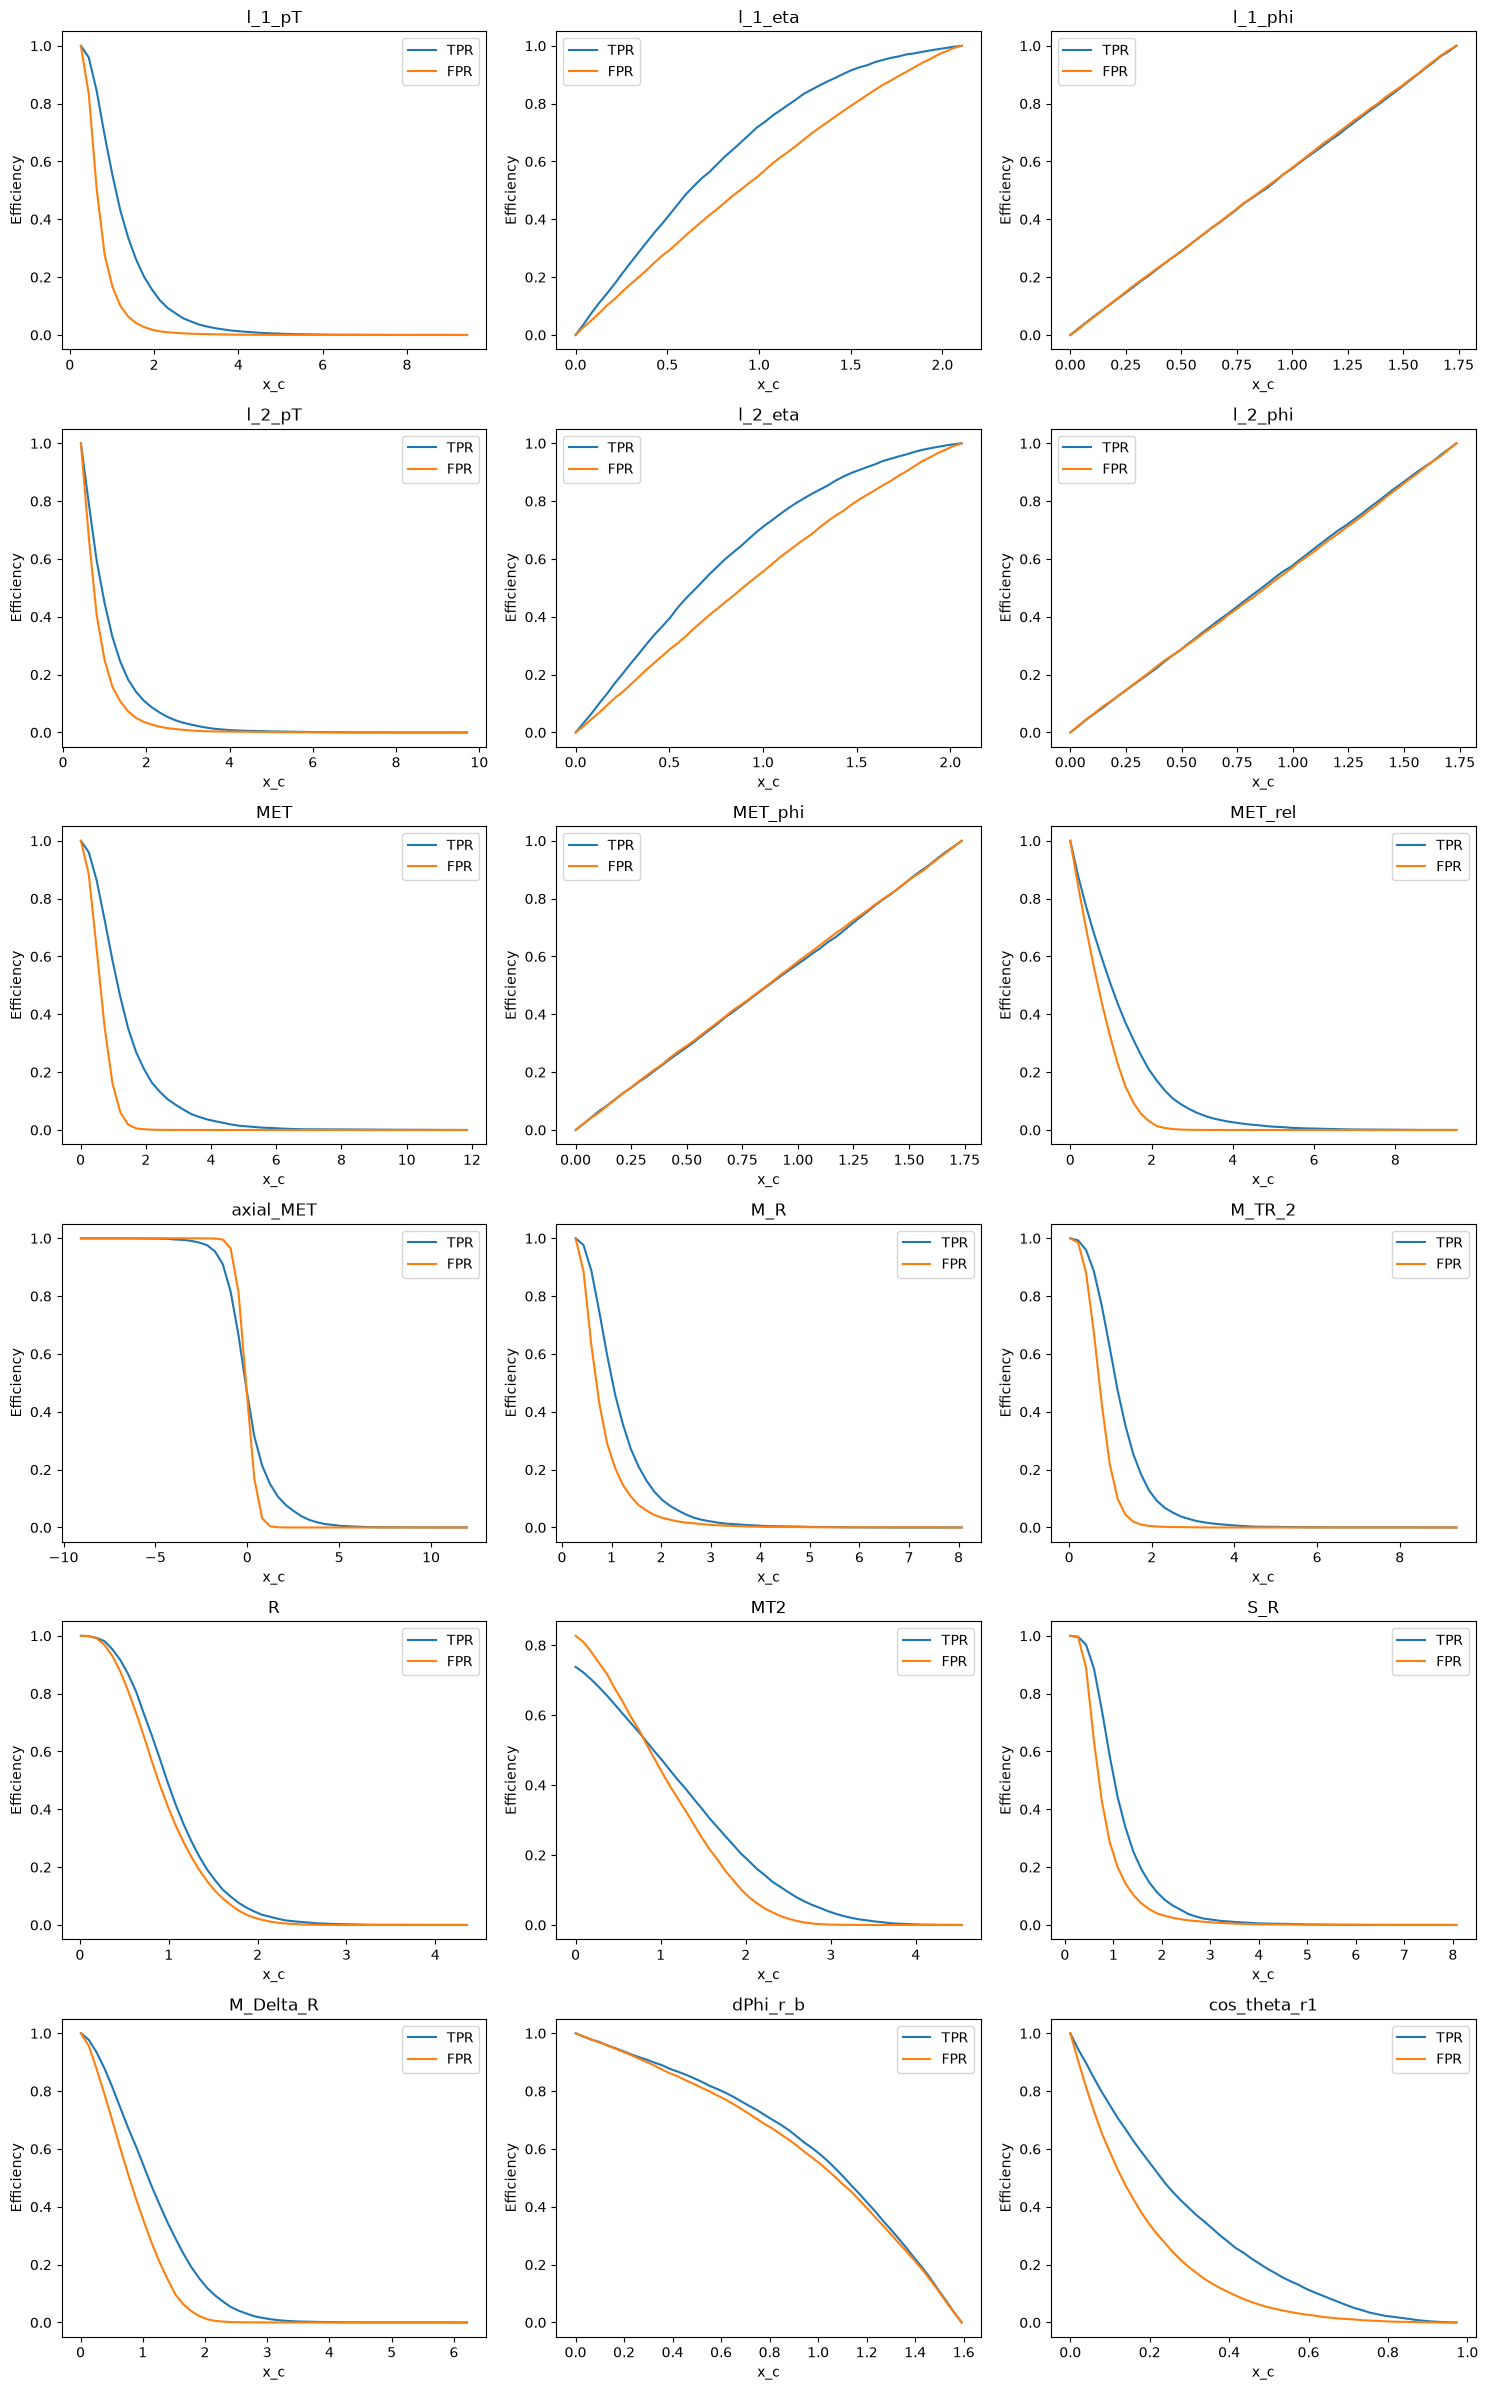

In [32]:
#5.2

selection_rules = {
    "l_1_pT": 1,
    "l_1_eta": 4,
    "l_1_phi": 4,
    "l_2_pT": 1,
    "l_2_eta": 4,
    "l_2_phi": 4,
    "MET": 1,
    "MET_phi": 4,
    "MET_rel": 1,
    "axial_MET": 1,
    "M_R": 1,
    "M_TR_2": 1,
    "R": 1,
    "MT2": 1,
    "S_R": 1,
    "M_Delta_R": 1,
    "dPhi_r_b": 1,
    "cos_theta_r1": 1
}

fig, axes = plt.subplots(6, 3, figsize=(15, 24))
axes = axes.flatten()

for i, variable in enumerate(observables):

    rule = selection_rules[variable]
    mu = sample[variable].mean()

    if rule in [1, 2]:
        x_values = np.linspace(
            sample[variable].min(),
            sample[variable].max(),
            50
        )
    else:
        max_distance = max(
            abs(sample[variable].min() - mu),
            abs(sample[variable].max() - mu)
        )
        x_values = np.linspace(0, max_distance, 50)

    tpr_values = []
    fpr_values = []

    for xc in x_values:

        eps_S, eps_B = get_efficiencies(
            sample, variable, rule, xc, mu
        )

        tpr_values.append(eps_S)
        fpr_values.append(eps_B)

    axes[i].plot(x_values, tpr_values, label="TPR")
    axes[i].plot(x_values, fpr_values, label="FPR")

    axes[i].set_title(variable)
    axes[i].set_xlabel("x_c")
    axes[i].set_ylabel("Efficiency")
    axes[i].legend()

plt.tight_layout()
plt.show()

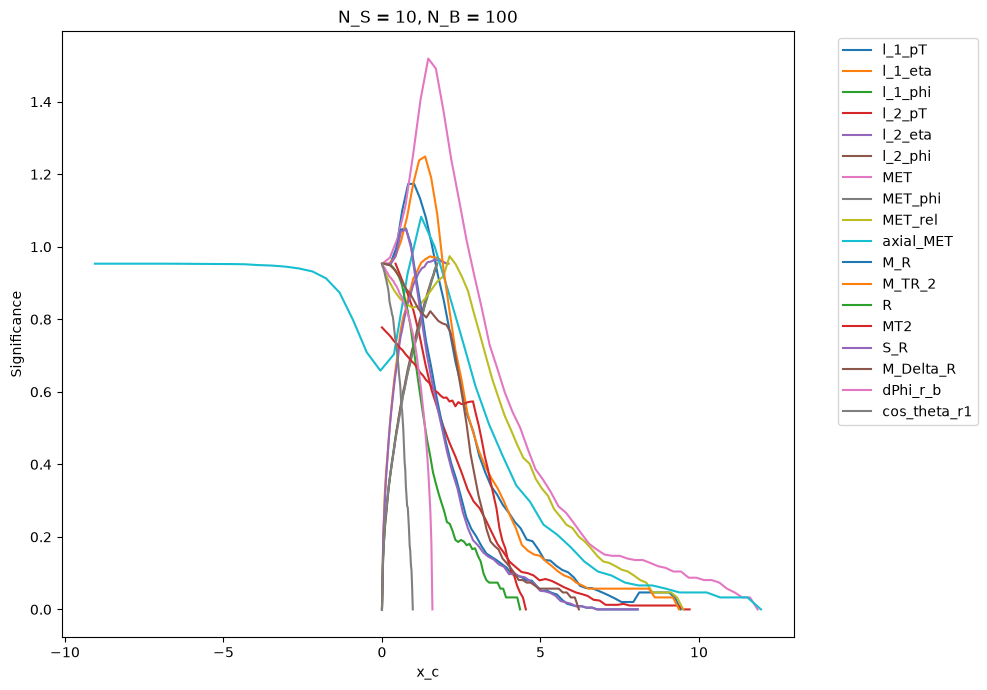

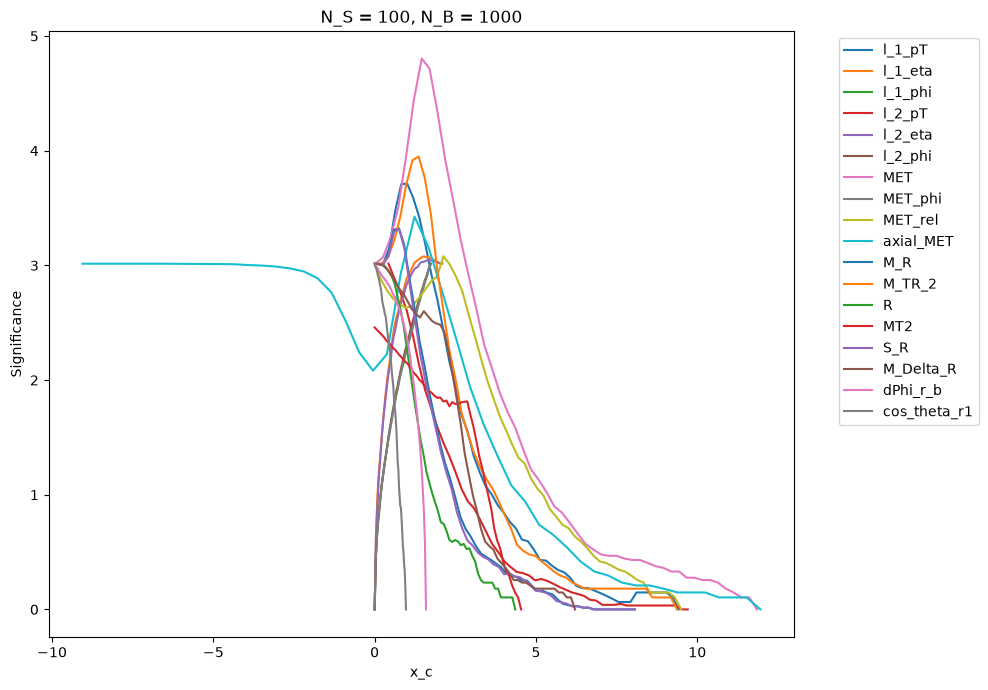

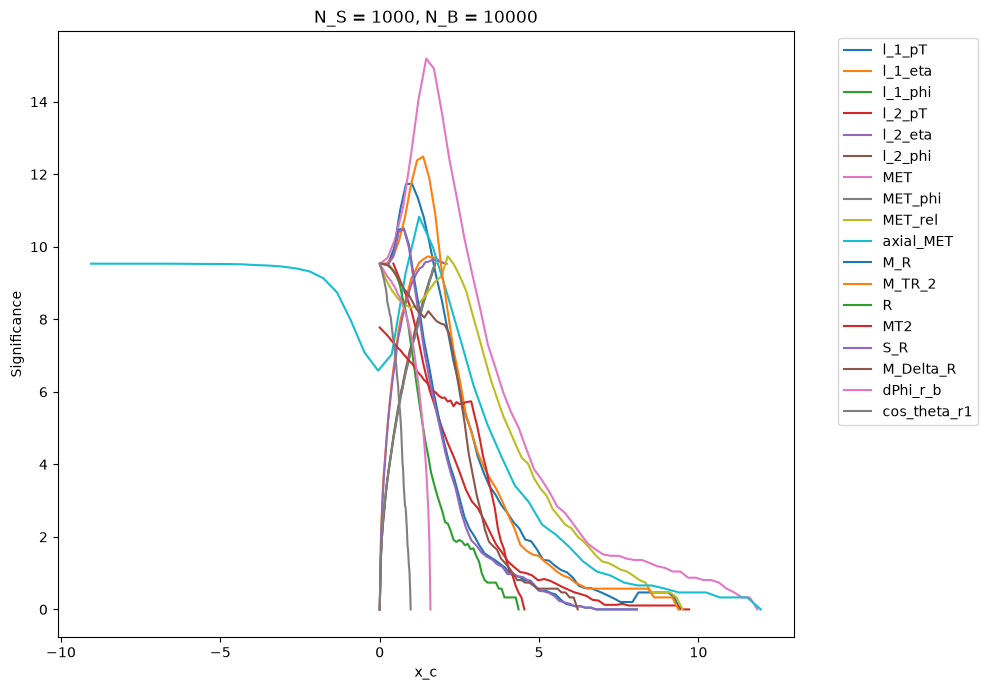

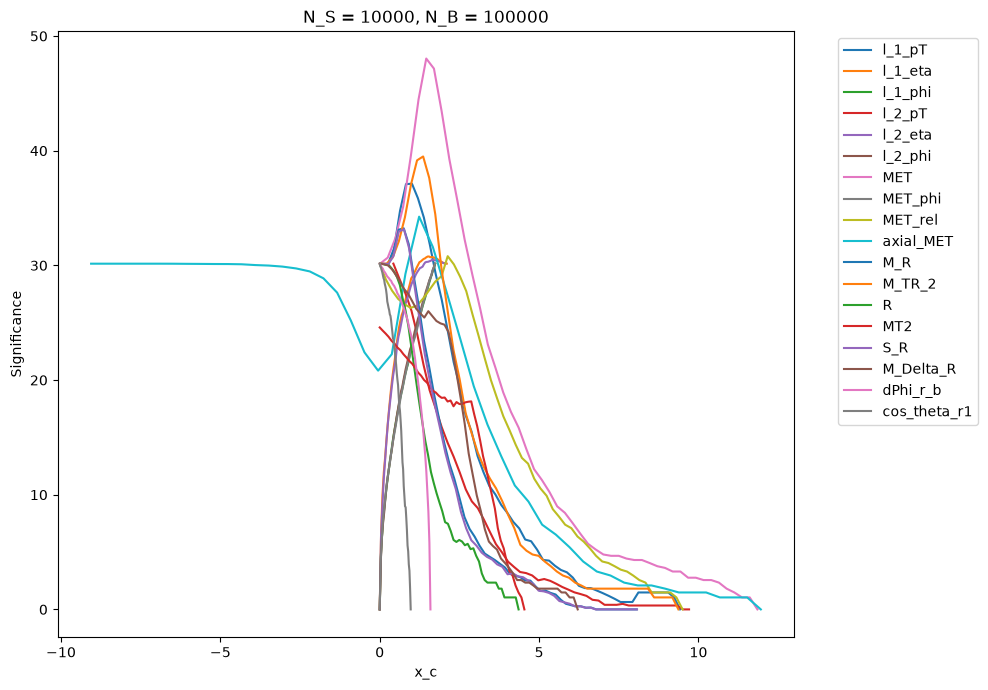

In [33]:
# 5.3

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

for NS, NB in scenarios:

    plt.figure(figsize=(10, 7))

    for variable in observables:

        rule = selection_rules[variable]
        mu = sample[variable].mean()

        if rule in [1, 2]:
            x_values = np.linspace(
                sample[variable].min(),
                sample[variable].max(),
                50
            )
        else:
            max_distance = max(
                abs(sample[variable].min() - mu),
                abs(sample[variable].max() - mu)
            )
            x_values = np.linspace(0, max_distance, 50)

        significance_values = []

        for xc in x_values:

            eps_S, eps_B = get_efficiencies(
                sample, variable, rule, xc, mu
            )

            NS_prime = eps_S * NS
            NB_prime = eps_B * NB

            if NS_prime + NB_prime > 0:
                significance = NS_prime / np.sqrt(
                    NS_prime + NB_prime
                )
            else:
                significance = 0

            significance_values.append(significance)

        plt.plot(x_values, significance_values, label=variable)

    plt.xlabel("x_c")
    plt.ylabel("Significance")
    plt.title("N_S = " + str(NS) + ", N_B = " + str(NB))
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




#6.1
For all four scenarios, I chose MET, l_1_pT, and MET_rel.

MET: x > 1.5
l_1_pT: x > 0.8
MET_rel: x > 2.5

In [34]:
cuts = [
    ("MET", 1.5),
    ("l_1_pT", 0.8),
    ("MET_rel", 2.5)
]

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

for NS, NB in scenarios:

    signal_data = df[df["signal"] == 1].copy()
    background_data = df[df["signal"] == 0].copy()

    original_signal = len(signal_data)
    original_background = len(background_data)

    table = []

    for variable, xc in cuts:

        signal_data = signal_data[signal_data[variable] > xc]
        background_data = background_data[background_data[variable] > xc]

        eps_S = len(signal_data) / original_signal
        eps_B = len(background_data) / original_background

        NS_prime = eps_S * NS
        NB_prime = eps_B * NB

        if NS_prime + NB_prime > 0:
            significance = NS_prime / np.sqrt(NS_prime + NB_prime)
        else:
            significance = 0

        table.append([
            variable + " > " + str(xc),
            round(eps_S, 3),
            round(eps_B, 3),
            round(NS_prime, 3),
            round(NB_prime, 3),
            round(significance, 3)
        ])

    print("Scenario: N_S =", NS, ", N_B =", NB)

    display(
        HTML(
            tabulate.tabulate(
                table,
                headers=[
                    "Selection",
                    "εS",
                    "εB",
                    "N'S",
                    "N'B",
                    "σS'"
                ],
                tablefmt="html"
            )
        )
    )

Scenario: N_S = 10 , N_B = 100


Selection,εS,εB,N'S,N'B,σS'
MET > 1.5,0.34,0.018,3.4,1.765,1.496
l_1_pT > 0.8,0.268,0.01,2.678,1.014,1.394
MET_rel > 2.5,0.09,0.002,0.896,0.175,0.866


Scenario: N_S = 100 , N_B = 1000


Selection,εS,εB,N'S,N'B,σS'
MET > 1.5,0.34,0.018,34.005,17.651,4.731
l_1_pT > 0.8,0.268,0.01,26.78,10.142,4.407
MET_rel > 2.5,0.09,0.002,8.961,1.754,2.738


Scenario: N_S = 1000 , N_B = 10000


Selection,εS,εB,N'S,N'B,σS'
MET > 1.5,0.34,0.018,340.047,176.506,14.962
l_1_pT > 0.8,0.268,0.01,267.796,101.42,13.937
MET_rel > 2.5,0.09,0.002,89.612,17.544,8.657


Scenario: N_S = 10000 , N_B = 100000


Selection,εS,εB,N'S,N'B,σS'
MET > 1.5,0.34,0.018,3400.47,1765.06,47.313
l_1_pT > 0.8,0.268,0.01,2677.97,1014.2,44.072
MET_rel > 2.5,0.09,0.002,896.116,175.435,27.375


First cut: MET > 1.5
Optimized second variable: MET_rel
Best second cut: 0.0
Best significance: 14.962


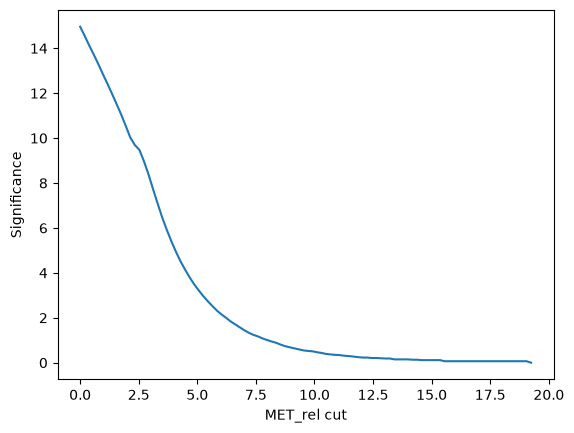

First cut: MET_rel > 2.5
Optimized second variable: MET
Best second cut: 1.796
Best significance: 9.595


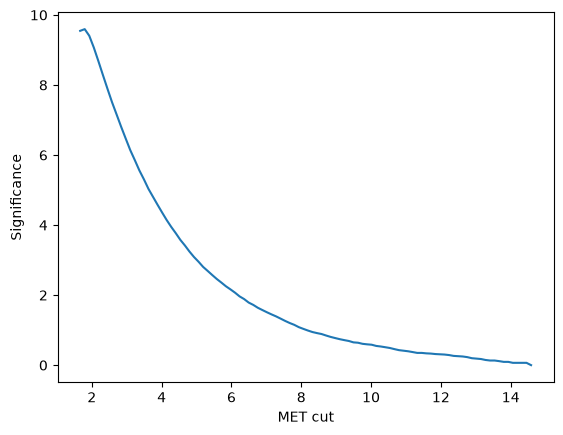

In [35]:

NS = 1000
NB = 10000

def optimize_second_cut(df, first_var, first_cut, second_var):

    selected = df[df[first_var] > first_cut]

    signal_total = len(df[df["signal"] == 1])
    background_total = len(df[df["signal"] == 0])

    x_values = np.linspace(
        selected[second_var].min(),
        selected[second_var].max(),
        100
    )

    significances = []

    for xc in x_values:

        final = selected[selected[second_var] > xc]

        eps_S = len(final[final["signal"] == 1]) / signal_total
        eps_B = len(final[final["signal"] == 0]) / background_total

        NS_prime = eps_S * NS
        NB_prime = eps_B * NB

        if NS_prime + NB_prime > 0:
            significance = NS_prime / np.sqrt(NS_prime + NB_prime)
        else:
            significance = 0

        significances.append(significance)

    best_index = np.argmax(significances)

    print("First cut:", first_var, ">", first_cut)
    print("Optimized second variable:", second_var)
    print("Best second cut:", round(x_values[best_index], 3))
    print("Best significance:", round(significances[best_index], 3))

    plt.plot(x_values, significances)
    plt.xlabel(second_var + " cut")
    plt.ylabel("Significance")
    plt.show()


optimize_second_cut(df, "MET", 1.5, "MET_rel")

optimize_second_cut(df, "MET_rel", 2.5, "MET")

#6.3
The order of the selections had an impact on the ultimate significance because variables are related. Applying the MET cut first and then optimizing MET_rel yielded a higher significance compared to optimizing MET_rel first and then applying the MET cut. This demonstrates the order of cuts can affect the outcome when variables are correlated.

## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



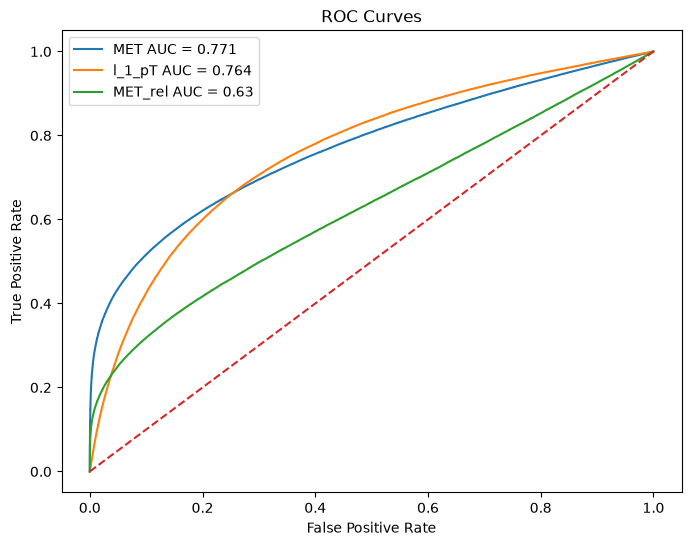

In [36]:
#7.1
from sklearn.metrics import roc_curve, auc

top_vars = ["MET", "l_1_pT", "MET_rel"]

plt.figure(figsize=(8, 6))

for variable in top_vars:

    y_true = df["signal"]
    scores = df[variable]

    fpr, tpr, thresholds = roc_curve(y_true, scores)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr,
             label=variable + " AUC = " + str(round(roc_auc, 3)))

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

In [37]:
#7.2
def plot_roc_curves(df, variables):

    plt.figure(figsize=(8, 6))

    for variable in variables:

        y_true = df["signal"]
        scores = df[variable]

        fpr, tpr, thresholds = roc_curve(y_true, scores)
        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            label=variable + " AUC = " + str(round(roc_auc, 3))
        )

    plt.plot([0, 1], [0, 1], linestyle="--")

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curves")
    plt.legend()
    plt.show()

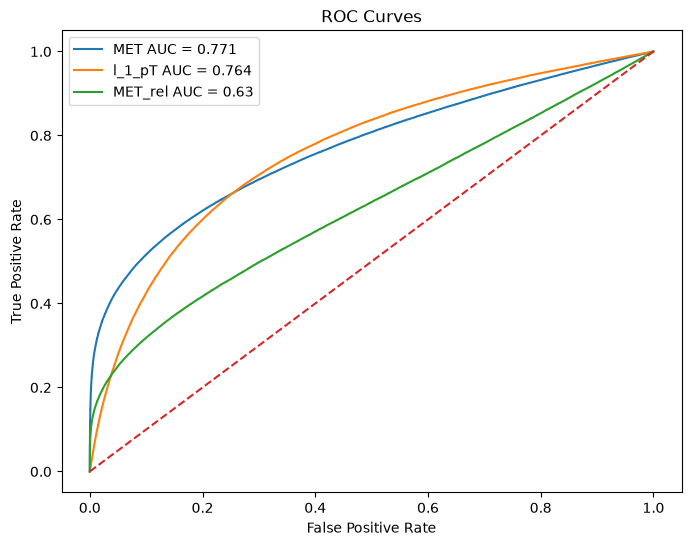

In [38]:
plot_roc_curves(df, ["MET", "l_1_pT", "MET_rel"])

After MET cut


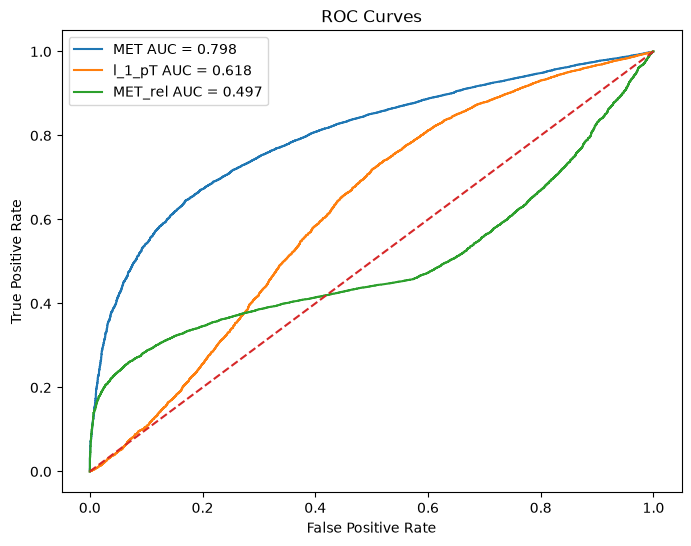

After MET and l_1_pT cuts


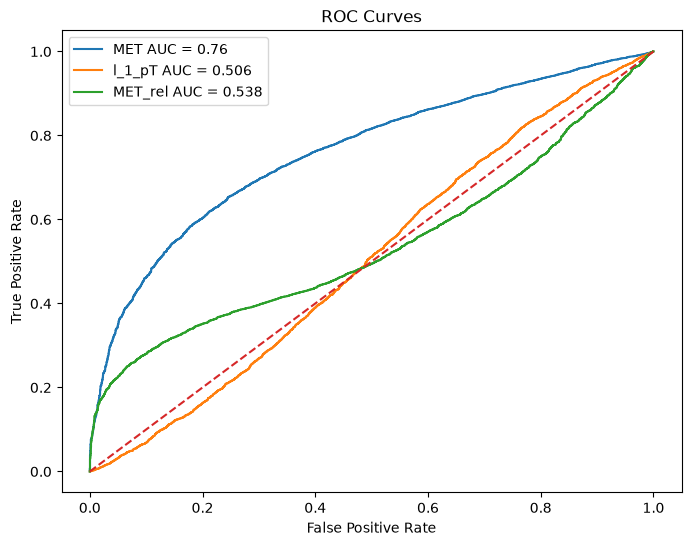

After all three cuts


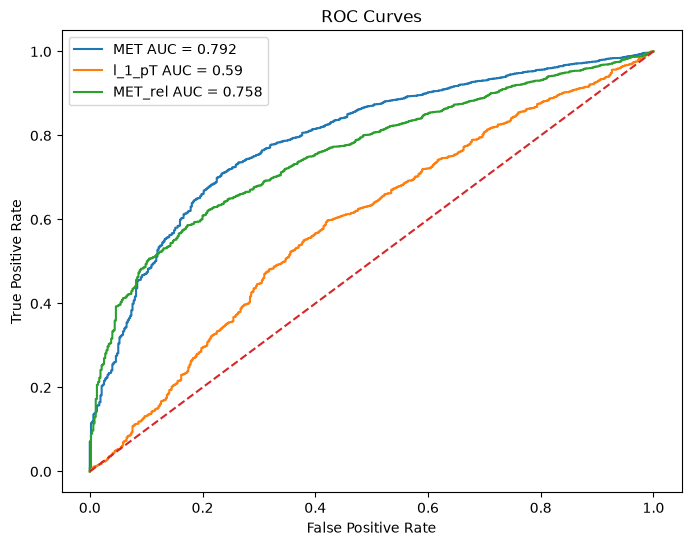

In [39]:
after_MET = df[df["MET"] > 1.5]

after_l1pT = after_MET[
    after_MET["l_1_pT"] > 0.8
]

after_METrel = after_l1pT[
    after_l1pT["MET_rel"] > 2.5
]

print("After MET cut")
plot_roc_curves(after_MET, ["MET", "l_1_pT", "MET_rel"])

print("After MET and l_1_pT cuts")
plot_roc_curves(after_l1pT, ["MET", "l_1_pT", "MET_rel"])

print("After all three cuts")
plot_roc_curves(after_METrel, ["MET", "l_1_pT", "MET_rel"])

Order: MET_rel -> l_1_pT -> MET


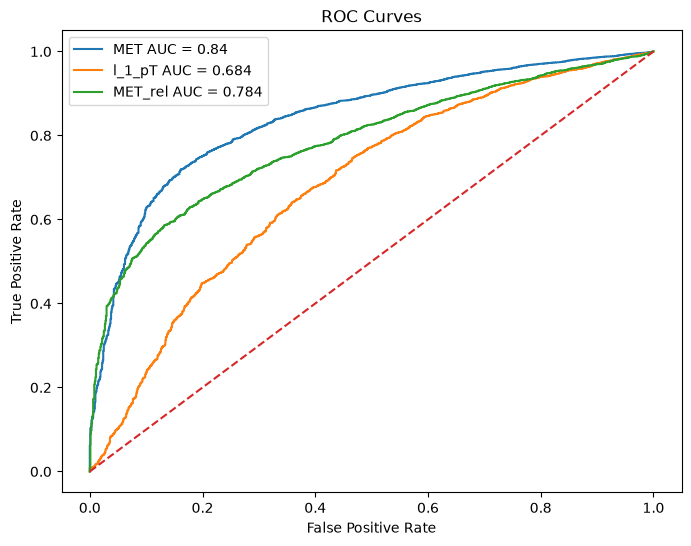

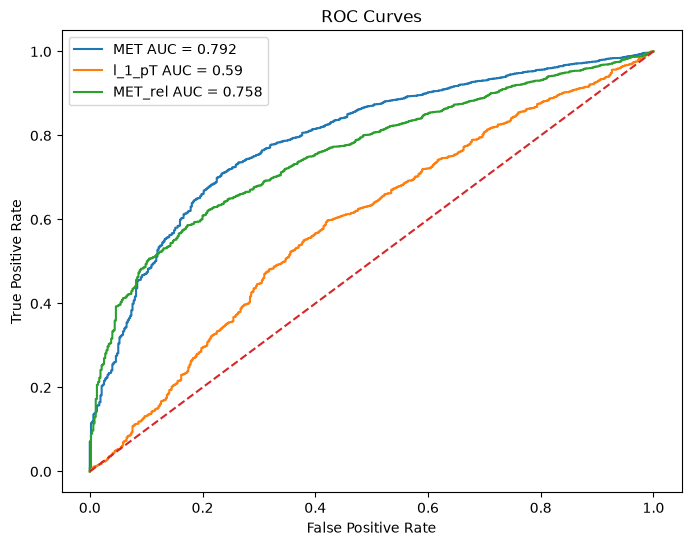

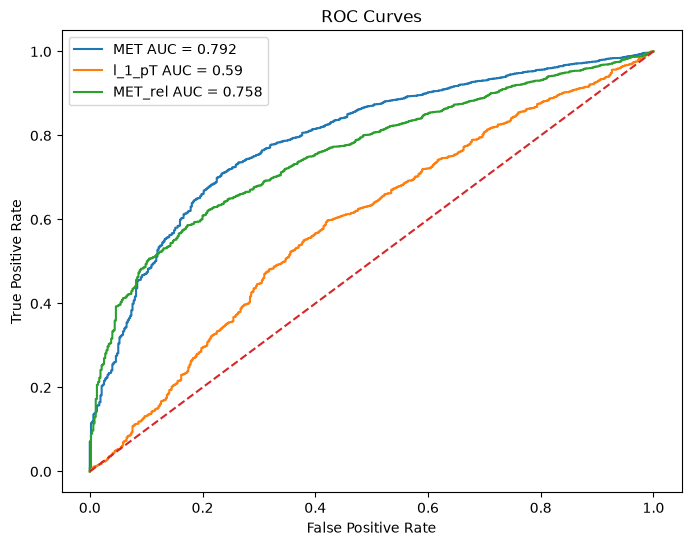

In [40]:
#7.4
after_METrel_first = df[df["MET_rel"] > 2.5]

after_l1pT_second = after_METrel_first[
    after_METrel_first["l_1_pT"] > 0.8
]

after_MET_last = after_l1pT_second[
    after_l1pT_second["MET"] > 1.5
]

print("Order: MET_rel -> l_1_pT -> MET")
plot_roc_curves(
    after_METrel_first,
    ["MET", "l_1_pT", "MET_rel"]
)

plot_roc_curves(
    after_l1pT_second,
    ["MET", "l_1_pT", "MET_rel"]
)

plot_roc_curves(
    after_MET_last,
    ["MET", "l_1_pT", "MET_rel"]
)

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

In [41]:
#8.1
X = df[VarNames[1:]]
signal = X[df["signal"] == 1]
background = X[df["signal"] == 0]

m1 = signal.mean().values
m2 = background.mean().values

diff = (m2 - m1).reshape(-1, 1)

SB = diff @ diff.T

signal_centered = signal.values - m1
background_centered = background.values - m2

SW = (
    signal_centered.T @ signal_centered
    + background_centered.T @ background_centered
)

print("Between-class matrix S_B:")
print(SB)

print("Within-class matrix S_W:")
print(SW)

Between-class matrix S_B:
[[ 2.87970231e-01  4.58922304e-04  4.67467434e-04  1.38148662e-01
   1.54068049e-03  3.66095560e-04  4.13461344e-01 -6.36618070e-04
   2.71136238e-01  8.54657090e-02  1.82331687e-01  2.66557653e-01
   5.53227373e-02  7.37824064e-02  1.74241790e-01  1.84116478e-01
   1.54056891e-02  5.66281031e-02]
 [ 4.58922304e-04  7.31359210e-07  7.44977113e-07  2.20159917e-04
   2.45529768e-06  5.83426339e-07  6.58910580e-04 -1.01454317e-06
   4.32094896e-04  1.36201995e-04  2.90571971e-04  4.24798257e-04
   8.81648006e-05  1.17582959e-04  2.77679548e-04  2.93416294e-04
   2.45511986e-05  9.02450903e-05]
 [ 4.67467434e-04  7.44977113e-07  7.58848582e-07  2.24259293e-04
   2.50101531e-06  5.94289733e-07  6.71179491e-04 -1.03343396e-06
   4.40140500e-04  1.38738075e-04  2.95982420e-04  4.32707998e-04
   8.98064286e-05  1.19772353e-04  2.82849940e-04  2.98879704e-04
   2.50083417e-05  9.19254533e-05]
 [ 1.38148662e-01  2.20159917e-04  2.24259293e-04  6.62743950e-02
   7.391144

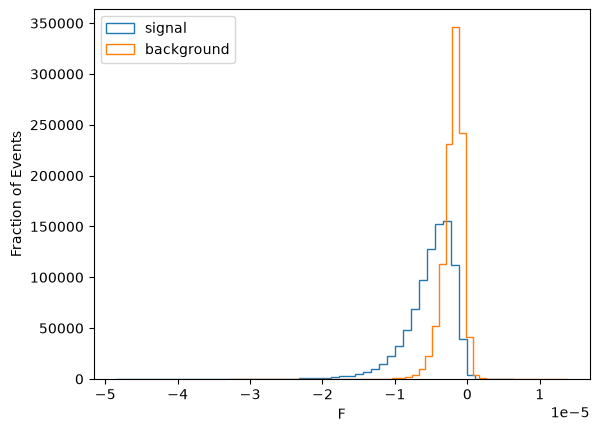

In [42]:
#8.2
w = np.linalg.solve(SW, m2 - m1)

F_signal = signal.values @ w
F_background = background.values @ w

plt.hist(F_signal, bins=50, histtype="step",
         density=True, label="signal")

plt.hist(F_background, bins=50, histtype="step",
         density=True, label="background")

plt.xlabel("F")
plt.ylabel("Fraction of Events")
plt.legend()
plt.show()

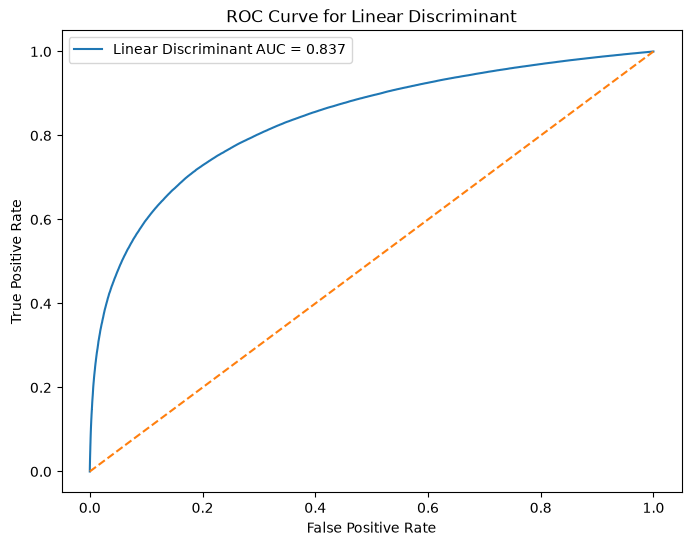

In [43]:
#8.3
F_all = df[VarNames[1:]].values @ w
y_true = df["signal"]

fpr, tpr, thresholds = roc_curve(y_true, -F_all)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label="Linear Discriminant AUC = " + str(round(roc_auc, 3)))
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Linear Discriminant")
plt.legend()
plt.show()

In [44]:
scores = -F_all

thresholds = np.linspace(scores.min(), scores.max(), 200)

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

for NS, NB in scenarios:

    significances = []

    for xc in thresholds:

        signal_eff = np.mean(scores[df["signal"] == 1] > xc)
        background_eff = np.mean(scores[df["signal"] == 0] > xc)

        NS_prime = signal_eff * NS
        NB_prime = background_eff * NB

        if NS_prime + NB_prime > 0:
            significance = NS_prime / np.sqrt(NS_prime + NB_prime)
        else:
            significance = 0

        significances.append(significance)

    best_index = np.argmax(significances)

    print("N_S =", NS, ", N_B =", NB)
    print("Best cut =", round(thresholds[best_index], 6))
    print("Maximum significance =", round(significances[best_index], 3))
    print()

N_S = 10 , N_B = 100
Best cut = 5e-06
Maximum significance = 1.531

N_S = 100 , N_B = 1000
Best cut = 5e-06
Maximum significance = 4.842

N_S = 1000 , N_B = 10000
Best cut = 5e-06
Maximum significance = 15.311

N_S = 10000 , N_B = 100000
Best cut = 5e-06
Maximum significance = 48.419

